In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import pandas as pd
import time

print("PyTorch Version:", torch.__version__)

PyTorch Version: 2.14.0+cpu


In [2]:
transform = transforms.ToTensor()

train_data = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_data = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training images:", len(train_data))
print("Testing images:", len(test_data))

100%|██████████| 9.91M/9.91M [00:04<00:00, 2.28MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 121kB/s]
100%|██████████| 1.65M/1.65M [00:04<00:00, 392kB/s] 
100%|██████████| 4.54k/4.54k [00:00<00:00, 4.26MB/s]

Training images: 60000
Testing images: 10000


In [3]:
train_loader = DataLoader(
    train_data,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_data,
    batch_size=64,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

Training batches: 938
Testing batches: 157


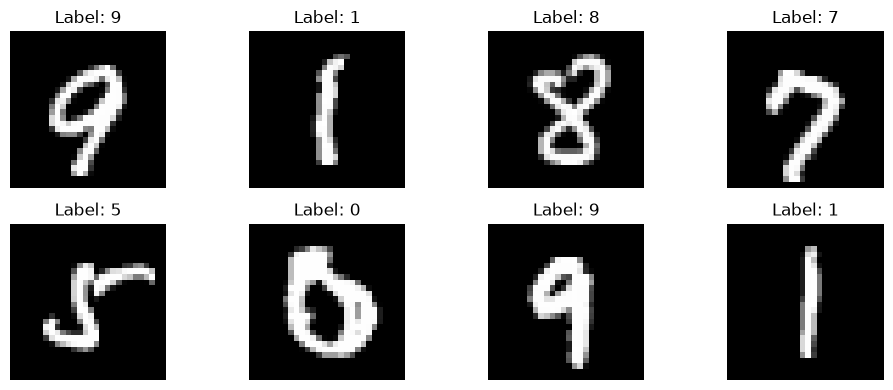

In [4]:
images, labels = next(iter(train_loader))

plt.figure(figsize=(10, 4))

for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i].squeeze(), cmap="gray")
    plt.title(f"Label: {labels[i].item()}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [5]:
class NeuralNetwork(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.network(x)

In [6]:
model = NeuralNetwork()

print(model)

NeuralNetwork(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=10, bias=True)
  )
)


In [7]:
images, labels = next(iter(train_loader))

outputs = model(images)

print("Images shape:", images.shape)
print("Outputs shape:", outputs.shape)

predictions = torch.argmax(outputs, dim=1)

print("Actual labels:", labels[:10].tolist())
print("Predictions:", predictions[:10].tolist())

Images shape: torch.Size([64, 1, 28, 28])
Outputs shape: torch.Size([64, 10])
Actual labels: [8, 0, 7, 0, 7, 9, 5, 4, 5, 6]
Predictions: [9, 7, 9, 9, 9, 9, 9, 9, 7, 9]


In [8]:
criterion = nn.CrossEntropyLoss()

print("Loss function:", criterion)

Loss function: CrossEntropyLoss()


In [9]:
def train_model(model, optimizer, train_loader, epochs=10):

    loss_history = []
    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        total_loss = 0

        for images, labels in train_loader:

            # 1. Clear previous gradients
            optimizer.zero_grad()

            # 2. Forward pass
            outputs = model(images)

            # 3. Calculate loss
            loss = criterion(outputs, labels)

            # 4. Backpropagation
            loss.backward()

            # 5. Update weights
            optimizer.step()

            total_loss += loss.item() * images.size(0)

        avg_loss = total_loss / len(train_loader.dataset)
        loss_history.append(avg_loss)

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Loss: {avg_loss:.4f}"
        )

    training_time = time.time() - start_time

    return loss_history, training_time

In [10]:
torch.manual_seed(42)

model_sgd = NeuralNetwork()

optimizer_sgd = optim.SGD(
    model_sgd.parameters(),
    lr=0.01
)

print("Training with SGD")

sgd_losses, sgd_time = train_model(
    model_sgd,
    optimizer_sgd,
    train_loader,
    epochs=10
)

Training with SGD
Epoch [1/10] Loss: 1.6658
Epoch [2/10] Loss: 0.5494
Epoch [3/10] Loss: 0.3934
Epoch [4/10] Loss: 0.3448
Epoch [5/10] Loss: 0.3155
Epoch [6/10] Loss: 0.2927
Epoch [7/10] Loss: 0.2738
Epoch [8/10] Loss: 0.2567
Epoch [9/10] Loss: 0.2422
Epoch [10/10] Loss: 0.2285


In [11]:
torch.manual_seed(42)

model_rmsprop = NeuralNetwork()

optimizer_rmsprop = optim.RMSprop(
    model_rmsprop.parameters(),
    lr=0.001
)

print("Training with RMSprop")

rmsprop_losses, rmsprop_time = train_model(
    model_rmsprop,
    optimizer_rmsprop,
    train_loader,
    epochs=10
)

Training with RMSprop
Epoch [1/10] Loss: 0.2685
Epoch [2/10] Loss: 0.1232
Epoch [3/10] Loss: 0.0844
Epoch [4/10] Loss: 0.0641
Epoch [5/10] Loss: 0.0503
Epoch [6/10] Loss: 0.0387
Epoch [7/10] Loss: 0.0317
Epoch [8/10] Loss: 0.0256
Epoch [9/10] Loss: 0.0211
Epoch [10/10] Loss: 0.0177


In [12]:
torch.manual_seed(42)

model_adam = NeuralNetwork()

optimizer_adam = optim.Adam(
    model_adam.parameters(),
    lr=0.001
)

print("Training with Adam")

adam_losses, adam_time = train_model(
    model_adam,
    optimizer_adam,
    train_loader,
    epochs=10
)

Training with Adam
Epoch [1/10] Loss: 0.3330
Epoch [2/10] Loss: 0.1355
Epoch [3/10] Loss: 0.0947
Epoch [4/10] Loss: 0.0716
Epoch [5/10] Loss: 0.0558
Epoch [6/10] Loss: 0.0426
Epoch [7/10] Loss: 0.0351
Epoch [8/10] Loss: 0.0285
Epoch [9/10] Loss: 0.0226
Epoch [10/10] Loss: 0.0203


In [13]:
print("SGD Training Time:", round(sgd_time, 2), "seconds")
print("RMSprop Training Time:", round(rmsprop_time, 2), "seconds")
print("Adam Training Time:", round(adam_time, 2), "seconds")

SGD Training Time: 55.1 seconds
RMSprop Training Time: 61.38 seconds
Adam Training Time: 69.56 seconds


In [14]:
print("SGD Final Loss:", round(sgd_losses[-1], 4))
print("RMSprop Final Loss:", round(rmsprop_losses[-1], 4))
print("Adam Final Loss:", round(adam_losses[-1], 4))

SGD Final Loss: 0.2285
RMSprop Final Loss: 0.0177
Adam Final Loss: 0.0203


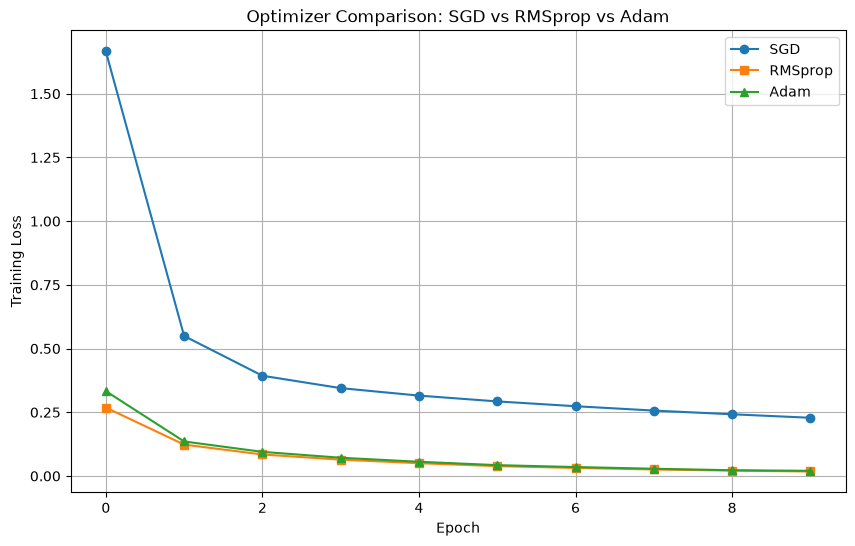

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(sgd_losses, label="SGD", marker="o")
plt.plot(rmsprop_losses, label="RMSprop", marker="s")
plt.plot(adam_losses, label="Adam", marker="^")

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Optimizer Comparison: SGD vs RMSprop vs Adam")

plt.legend()
plt.grid(True)
plt.show()

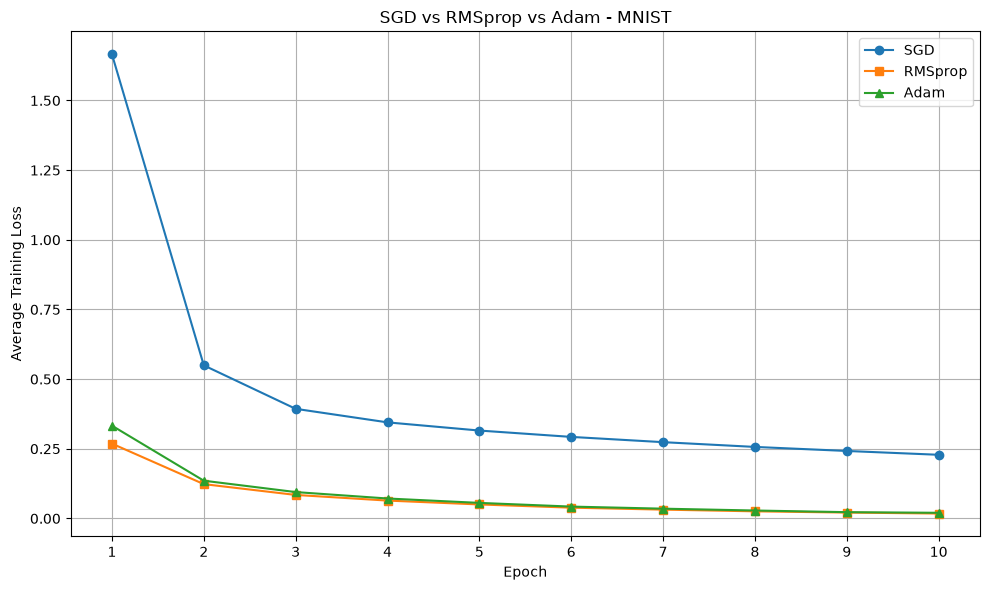

In [16]:
epochs = range(1, len(sgd_losses) + 1)

plt.figure(figsize=(10, 6))

plt.plot(epochs, sgd_losses, marker="o", label="SGD")
plt.plot(epochs, rmsprop_losses, marker="s", label="RMSprop")
plt.plot(epochs, adam_losses, marker="^", label="Adam")

plt.xlabel("Epoch")
plt.ylabel("Average Training Loss")
plt.title("SGD vs RMSprop vs Adam - MNIST")
plt.xticks(epochs)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("optimizer_loss_comparison.png", dpi=300)
plt.show()

In [17]:
comparison = pd.DataFrame({
    "Optimizer": ["SGD", "RMSprop", "Adam"],
    "Final Loss": [
        sgd_losses[-1],
        rmsprop_losses[-1],
        adam_losses[-1]
    ],
    "Training Time (s)": [
        sgd_time,
        rmsprop_time,
        adam_time
    ]
})

print(comparison.round(4))

  Optimizer  Final Loss  Training Time (s)
0       SGD      0.2285            55.1040
1   RMSprop      0.0177            61.3783
2      Adam      0.0203            69.5645


In [18]:
best_optimizer = comparison.loc[
    comparison["Final Loss"].idxmin(),
    "Optimizer"
]

print("Lowest Final Training Loss:", best_optimizer)

Lowest Final Training Loss: RMSprop


In [19]:
def evaluate_model(model, test_loader):

    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in test_loader:

            outputs = model(images)

            predictions = torch.argmax(outputs, dim=1)

            correct += (predictions == labels).sum().item()

            total += labels.size(0)

    accuracy = 100 * correct / total

    return accuracy

In [20]:
sgd_accuracy = evaluate_model(model_sgd, test_loader)

rmsprop_accuracy = evaluate_model(model_rmsprop, test_loader)

adam_accuracy = evaluate_model(model_adam, test_loader)

print(f"SGD Accuracy: {sgd_accuracy:.2f}%")
print(f"RMSprop Accuracy: {rmsprop_accuracy:.2f}%")
print(f"Adam Accuracy: {adam_accuracy:.2f}%")

SGD Accuracy: 93.53%
RMSprop Accuracy: 97.95%
Adam Accuracy: 97.92%


In [21]:
results = pd.DataFrame({
    "Optimizer": ["SGD", "RMSprop", "Adam"],
    "Final Loss": [
        sgd_losses[-1],
        rmsprop_losses[-1],
        adam_losses[-1]
    ],
    "Accuracy (%)": [
        sgd_accuracy,
        rmsprop_accuracy,
        adam_accuracy
    ],
    "Training Time (sec)": [
        sgd_time,
        rmsprop_time,
        adam_time
    ]
})

print(results.round(4))

  Optimizer  Final Loss  Accuracy (%)  Training Time (sec)
0       SGD      0.2285         93.53              55.1040
1   RMSprop      0.0177         97.95              61.3783
2      Adam      0.0203         97.92              69.5645


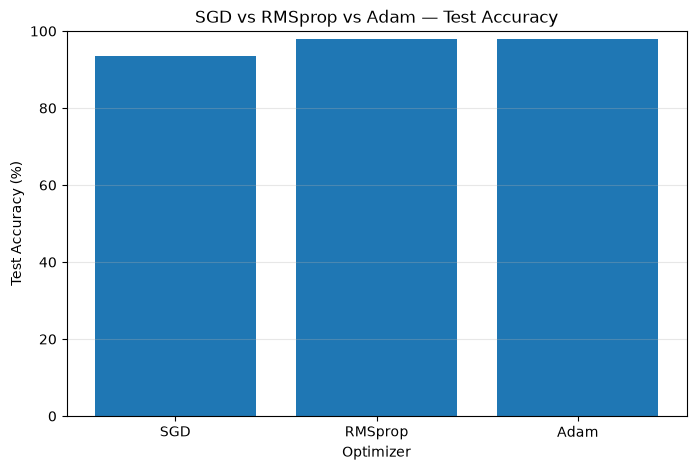

In [22]:
plt.figure(figsize=(8, 5))

plt.bar(
    results["Optimizer"],
    results["Accuracy (%)"]
)

plt.xlabel("Optimizer")
plt.ylabel("Test Accuracy (%)")
plt.title("SGD vs RMSprop vs Adam — Test Accuracy")

plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

plt.savefig(
    "optimizer_accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
best_accuracy = results.loc[
    results["Accuracy (%)"].idxmax()
]

fastest_optimizer = results.loc[
    results["Training Time (sec)"].idxmin()
]

lowest_loss = results.loc[
    results["Final Loss"].idxmin()
]

print("Best Accuracy:", best_accuracy["Optimizer"])
print("Fastest Training:", fastest_optimizer["Optimizer"])
print("Lowest Training Loss:", lowest_loss["Optimizer"])

Best Accuracy: RMSprop
Fastest Training: SGD
Lowest Training Loss: RMSprop
